In [1]:
# Instal required packages

import pandas as pd
import joblib 

In [2]:
# Load external validation dataset
df_iol =  pd.read_csv(
    r"/Users/nigus/Library/CloudStorage/OneDrive-MonashUniversity/PhD/CSAI validation/df_iol_final.csv",
    low_memory=False)

In [3]:
df_iol.shape

(17850, 258)

In [4]:
df_iol.columns.tolist()

['mother_episode_id',
 'weight_at_birth_admission_since_2017',
 'mother_ur',
 'baby_episode_id',
 'plurality',
 'gravida',
 'parity',
 'baby_num',
 'an_procedures',
 'birth_place',
 'pref_language',
 'postcode_x',
 'mother_indigenous',
 'mother_diet',
 'fam_hist',
 'fam_hist_text',
 'mother_age',
 'est_gest',
 'baby_ward',
 'birth_date',
 'latest_care_model',
 'admit_source',
 'intended_place_of_birth_y_n',
 'account_class',
 'marital_status',
 'country_of_birth',
 'liquor',
 'maternal_medical_conditions',
 'maternal_medical_conditions_text',
 'obstetric_complications',
 'obstetric_comps_text',
 'onset_labour',
 'induction_main_indication',
 'induction_mode',
 'induction_text',
 'augmentation',
 'onset_date',
 'onset_time',
 'length_1st_stage',
 'fetal_monitoring_not_in_labour',
 'fetal_monitoring_in_labour',
 'birth_type',
 'past_history',
 'presentation',
 'labour_analgesia',
 'birth_anaesthesia',
 'indication_for_instrumental_main',
 'labour_complications',
 'labour_comps_text',
 'p

In [5]:
# Create admission time variable
import numpy as np
## Convert to hours (0–24)
df_iol['admission_hour'] = df_iol['birth_admission_time'] * 24

## Create day/night variable
df_iol['admission_daynight'] = np.where(
    (df_iol['admission_hour'] >= 8) & (df_iol['admission_hour'] < 20),
    0,  # Day
    1   # Night
)

In [14]:
# Desciptive table for predictors 

import pandas as pd
import numpy as np

continuous_vars = [
    'bmi',
    'mother_age',
    'mother_weight',
    'mother_height'
]

categorical_vars = [
    'planned_ga',
    'parity_rec',
    'rurality',
    'seifa_quintile',
    'smoking_before_20w',
    'dm',
    'preeclampsia',
    'birth_private_hospital',
    'birth_region',
    'ascl_group_rec',
    'gdm',
    'prior_gdm',
    'prior_preeclampsia',
    'htn',
    'admission_daynight'
]

table_rows = []

# =====================================================
# Overall sample size and CS groups
# =====================================================

n_total = len(df_iol)

n_cs0 = (df_iol['cs_delivery'] == 0).sum()
n_cs1 = (df_iol['cs_delivery'] == 1).sum()

# =====================================================
# Overall row
# =====================================================

table_rows.append([
    'Overall',
    f"{n_total} (100.0%)",
    f"{n_cs0} ({100*n_cs0/n_total:.1f}%)",
    f"{n_cs1} ({100*n_cs1/n_total:.1f}%)"
])

# =====================================================
# Continuous variables
# =====================================================

for var in continuous_vars:

    overall = df_iol[var].dropna()
    cs0 = df_iol.loc[df_iol['cs_delivery'] == 0, var].dropna()
    cs1 = df_iol.loc[df_iol['cs_delivery'] == 1, var].dropna()

    table_rows.append([
        var,
        f"{overall.mean():.1f} ({overall.std():.1f})",
        f"{cs0.mean():.1f} ({cs0.std():.1f})",
        f"{cs1.mean():.1f} ({cs1.std():.1f})"
    ])

# =====================================================
# Categorical variables
# =====================================================

for var in categorical_vars:

    # Keep missing values excluded from the category levels
    levels = sorted(df_iol[var].dropna().unique())

    for level in levels:

        # Overall
        n_overall = (df_iol[var] == level).sum()
        pct_overall = 100 * n_overall / n_total

        # CS = 0
        n0 = (
            (df_iol[var] == level) &
            (df_iol['cs_delivery'] == 0)
        ).sum()

        pct0 = 100 * n0 / n_cs0

        # CS = 1
        n1 = (
            (df_iol[var] == level) &
            (df_iol['cs_delivery'] == 1)
        ).sum()

        pct1 = 100 * n1 / n_cs1

        table_rows.append([
            f"{var}: {level}",
            f"{n_overall} ({pct_overall:.1f}%)",
            f"{n0} ({pct0:.1f}%)",
            f"{n1} ({pct1:.1f}%)"
        ])

# =====================================================
# Final table
# =====================================================

table1 = pd.DataFrame(
    table_rows,
    columns=[
        'Variable',
        'Overall',
        'CS = 0',
        'CS = 1'
    ]
)

table1

,Variable,Overall,CS = 0,CS = 1
0,Overall,17850 (100.0%),13338 (74.7%),4512 (25.3%)
1,bmi,27.2 (6.9),26.9 (6.8),28.1 (7.2)
2,mother_age,30.6 (5.2),30.6 (5.2),30.6 (5.0)
3,mother_weight,73.6 (20.6),73.2 (20.3),75.0 (21.3)
4,mother_height,162.7 (7.0),163.2 (6.9),161.4 (7.0)
5,planned_ga: 37,2007 (11.2%),1647 (12.3%),360 (8.0%)
6,planned_ga: 38,4963 (27.8%),3910 (29.3%),1053 (23.3%)
7,planned_ga: 39,5387 (30.2%),4132 (31.0%),1255 (27.8%)
8,planned_ga: 40,3545 (19.9%),2483 (18.6%),1062 (23.5%)
9,planned_ga: 41,1948 (10.9%),1166 (8.7%),782 (17.3%)


In [16]:
## Export the table
table1.to_excel(
    "Table1_Characteristics_by_CS.xlsx",
    index=False
)

In [6]:
# Load developed model pipeline

pipeline = r"/Users/nigus/Library/CloudStorage/OneDrive-MonashUniversity/PhD/CSAI validation/Original model/best_pipeline_xgboost.clf"
model_pipeline = joblib.load(pipeline)

/opt/anaconda3/lib/python3.13/pickle.py:1760: UserWarning: [15:16:50] WARNING: /Users/runner/work/xgboost/xgboost/src/gbm/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)
/opt/anaconda3/lib/python3.13/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator RFECV from version 1.4.1.post1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-p

In [7]:
## Rename some variables to match CSAI model
mapping = {
    'maternal_age': 'mother_age',
    'bmi_num': 'bmi',
    'rurality_2021_new': 'rurality',
    'parity_rec': 'parity',
    'birth_region': 'cob_region',
    'planned_ga': 'gest_weeks',
    'smoking_before_20w': 'smoke_b20',
    'dm': 'pre_diab',
    'birth_private_hospital': 'private_hospital'
}

# Remove duplicate columns - more robust approach
df_iol = df_iol.loc[:, ~df_iol.columns.duplicated(keep='first')]

# Check for duplicates before renaming
print("Columns before renaming:", df_iol.columns.tolist())
print("Duplicate columns:", df_iol.columns[df_iol.columns.duplicated()].tolist())

df_iol = df_iol.rename(columns=mapping)

# Check for duplicates after renaming (in case mapping creates duplicates)
print("Columns after renaming:", df_iol.columns.tolist())
print("Duplicate columns after renaming:", df_iol.columns[df_iol.columns.duplicated()].tolist())

# Remove any duplicates that may have been created during renaming
df_iol = df_iol.loc[:, ~df_iol.columns.duplicated(keep='first')]

## Create missing variables
df_iol["gest_weeks_first_visit"] = 99

## ensure smoke_a20 exists
if "smoke_a20" not in df_iol.columns:
    df_iol["smoke_a20"] = 9   # or proper derived logic

# (ensure other derived vars exist if needed)
if "num_ant_visit" not in df_iol.columns:
    df_iol["num_ant_visit"] = 99

# 3. Force alignment to EXACT model schema
expected_cols = model_pipeline.feature_names_in_

# Final check for duplicates before reindexing
if df_iol.columns.duplicated().any():
    print("Warning: Still have duplicates, removing them...")
    df_iol = df_iol.loc[:, ~df_iol.columns.duplicated(keep='first')]

X_val = df_iol.reindex(columns=expected_cols)

# 4. Now validate
assert list(X_val.columns) == list(expected_cols)

print("Schema match confirmed:", X_val.shape)
print(X_val.columns.tolist())

Columns before renaming: ['mother_episode_id', 'weight_at_birth_admission_since_2017', 'mother_ur', 'baby_episode_id', 'plurality', 'gravida', 'parity', 'baby_num', 'an_procedures', 'birth_place', 'pref_language', 'postcode_x', 'mother_indigenous', 'mother_diet', 'fam_hist', 'fam_hist_text', 'mother_age', 'est_gest', 'baby_ward', 'birth_date', 'latest_care_model', 'admit_source', 'intended_place_of_birth_y_n', 'account_class', 'marital_status', 'country_of_birth', 'liquor', 'maternal_medical_conditions', 'maternal_medical_conditions_text', 'obstetric_complications', 'obstetric_comps_text', 'onset_labour', 'induction_main_indication', 'induction_mode', 'induction_text', 'augmentation', 'onset_date', 'onset_time', 'length_1st_stage', 'fetal_monitoring_not_in_labour', 'fetal_monitoring_in_labour', 'birth_type', 'past_history', 'presentation', 'labour_analgesia', 'birth_anaesthesia', 'indication_for_instrumental_main', 'labour_complications', 'labour_comps_text', 'peri_status', 'estimated_

In [8]:
# Check missingness in the preditors 

import pandas as pd

import pandas as pd

predictors = [
    'parity', 'gest_weeks', 'seifa', 'rurality', 'smoke_b20',
    'smoke_a20', 'pre_diab', 'pre_hyper', 'preeclampsia',
    'gest_hyper', 'gest_diab', 'bmi', 'mother_age',
    'private_hospital', 'cob_region', 'gravidity',
    'gest_weeks_first_visit', 'num_ant_visit'
]

# continuous variables 
continuous = [
    'gest_weeks', 'bmi', 'mother_age',
    'gest_weeks_first_visit', 'num_ant_visit'
]

print("="*70)

for var in predictors:

    print(f"\n{var}")
    print("-"*70)

    if var in continuous:

        print(df_iol[var].describe())

        for code in [9, 99, 999]:
            n = (df_iol[var] == code).sum()
            if n > 0:
                print(f"Value {code}: {n} ({100*n/len(df_iol):.2f}%)")

    else:

        print(df_iol[var].value_counts(dropna=False).sort_index())

    print("="*70)


parity
----------------------------------------------------------------------
parity
0     9681
1     4805
2     2019
3      758
4      335
5      151
6       54
7       22
8       10
9        6
10       5
11       4
Name: count, dtype: int64

gest_weeks
----------------------------------------------------------------------
count    17850.000000
mean        38.913950
std          1.164296
min         37.000000
25%         38.000000
50%         39.000000
75%         40.000000
max         41.000000
Name: gest_weeks, dtype: float64

seifa
----------------------------------------------------------------------
seifa
1    3984
2    2735
3    4334
4    4615
5    2182
Name: count, dtype: int64

rurality
----------------------------------------------------------------------
rurality
Inner Regional Australia       644
Major Cities of Australia    17151
Outer Regional Australia        51
Remote Australia                 3
Very Remote Australia            1
Name: count, dtype: int64

smoke_b20
--

In [9]:
# Handle level mismatches between current data and original model expectations

# 1. PARITY
df_iol['parity'] = df_iol['parity'].apply(lambda x: 0 if x == 0 else (1 if x >= 1 else 9))

# 2. GEST_WEEKS: Add missing category 99 for any potential missing values
df_iol['gest_weeks'] = df_iol['gest_weeks'].fillna(99)

# 3. SEIFA: Add missing category 9 for any potential missing values
df_iol['seifa'] = df_iol['seifa'].fillna(9)

# 4. RURALITY: convert to numeric
rurality_mapping = {
    'Major Cities of Australia': 1,
    'Inner Regional Australia': 2, 
    'Outer Regional Australia': 3,
    'Remote Australia': 4,
    'Very Remote Australia': 5
}
df_iol['rurality'] = df_iol['rurality'].map(rurality_mapping).fillna(9)

# 5. SMOKE_B20: Convert to numeric
smoke_b20_mapping = {
    'No': 0,
    'Yes': 1,
    'Unknown': 9
}
df_iol['smoke_b20'] = df_iol['smoke_b20'].map(smoke_b20_mapping).fillna(9)

# 7. BMI: Replace any missing values with 99
df_iol['bmi'] = df_iol['bmi'].fillna(99)

# 8. MOTHER_AGE: Replace any missing values with 99
df_iol['mother_age'] = df_iol['mother_age'].fillna(99)

# 9. PRIVATE_HOSPITAL: ensure missing values are coded as 9
df_iol['private_hospital'] = df_iol['private_hospital'].fillna(9)

# 10. COB_REGION: Replace NaN with 9
df_iol['cob_region'] = df_iol['cob_region'].fillna(9)

# 11. GRAVIDITY: Replace any missing values with 99  
df_iol['gravidity'] = df_iol['gravidity'].fillna(99)

# Verify the transformations
print("After level alignment:")
for col in ['parity', 'gest_weeks', 'seifa', 'rurality', 'smoke_b20', 'smoke_a20', 
           'pre_diab', 'pre_hyper', 'preeclampsia', 'gest_hyper', 'gest_diab',
           'private_hospital', 'cob_region']:
    print(f"{col}: {sorted(df_iol[col].unique())}")

After level alignment:
parity: [np.int64(0), np.int64(1)]
gest_weeks: [np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41)]
seifa: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
rurality: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
smoke_b20: [np.int64(0), np.int64(1), np.int64(9)]
smoke_a20: [np.int64(0), np.int64(1), np.int64(9)]
pre_diab: [np.int64(0), np.int64(1)]
pre_hyper: [np.int64(0), np.int64(1)]
preeclampsia: [np.int64(0), np.int64(1)]
gest_hyper: [np.int64(0), np.int64(1)]
gest_diab: [np.int64(0), np.int64(1)]
private_hospital: [np.int64(0)]
cob_region: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(9.0)]


In [10]:
# Update the model (extension) with new features in the validation dataset #

import numpy as np
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier


# STEP 1: Extract RFECV-selected features

rfecv = model_pipeline.named_steps["feature_selection"]  # original features from the saved pipeline 

rfecv_features = rfecv.feature_names_in_
selected_mask = rfecv.support_

selected_original_features = list(
    np.array(rfecv_features)[selected_mask]
)

print("RFECV-selected features (10):")
print(selected_original_features)

# STEP 2: Define new predictors

new_features = [
    'ascl_group_rec',
    'gdm',
    'prior_gdm',
    'prior_preeclampsia',
    'htn',
    'admission_daynight',
    'mother_weight',
    'mother_height'
]

all_features = selected_original_features + new_features

print("\nFinal feature set:", all_features)
print("Total features:", len(all_features))

# STEP 3: Prepare extended dataset

df_extended = df_iol.copy()

for f in new_features:
    if f not in df_extended.columns:
        if f in ['mother_weight', 'mother_height']:
            df_extended[f] = np.nan
        else:
            df_extended[f] = 0

# Apply one-hot encoding to categorical columns
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# One-hot encode 'ascl_group_rec' (categorical)
if 'ascl_group_rec' in df_extended.columns and df_extended['ascl_group_rec'].dtype == 'object':
    # Create one-hot encoded columns
    ascl_encoded = pd.get_dummies(df_extended['ascl_group_rec'], prefix='ascl_group_rec', drop_first=False)
    
    # Drop original categorical column and add encoded columns
    df_extended = df_extended.drop('ascl_group_rec', axis=1)
    df_extended = pd.concat([df_extended, ascl_encoded], axis=1)
    
    # Update feature list to include new one-hot encoded columns
    all_features = [f for f in all_features if f != 'ascl_group_rec']  # Remove original column
    all_features.extend(ascl_encoded.columns.tolist())  # Add one-hot encoded columns

X_extended = df_extended.reindex(columns=all_features)
y = df_extended["cs_delivery"]

print("Training shape after one-hot encoding:", X_extended.shape)
print("New feature columns:", [col for col in X_extended.columns if 'ascl_group_rec' in col])

# STEP 4: Define XGBoost with exact hyperparameters from the published model

xgb = XGBClassifier(
    n_estimators=52,
    learning_rate=0.50,
    max_depth=3,
    subsample=0.93,
    colsample_bytree=0.81,
    gamma=1.91,
    eval_metric="logloss",
    random_state=42
)

# STEP 5: Build new pipeline
# (RFECV removed → now fully extended model)

new_pipeline = Pipeline([
    ("classifier", xgb)
])

# STEP 6: Train model

new_pipeline.fit(X_extended, y)

# STEP 7: Verification

print("\n=== MODEL UPDATE COMPLETE ===")
print(f"Original RFECV features: {len(selected_original_features)}")
print(f"New features added: {len(new_features)}")
print(f"Total features used: {len(all_features)}")

RFECV-selected features (10):
['parity', 'gest_weeks', 'rurality', 'smoke_b20', 'pre_diab', 'preeclampsia', 'bmi', 'mother_age', 'private_hospital', 'cob_region']

Final feature set: ['parity', 'gest_weeks', 'rurality', 'smoke_b20', 'pre_diab', 'preeclampsia', 'bmi', 'mother_age', 'private_hospital', 'cob_region', 'ascl_group_rec', 'gdm', 'prior_gdm', 'prior_preeclampsia', 'htn', 'admission_daynight', 'mother_weight', 'mother_height']
Total features: 18
Training shape after one-hot encoding: (17850, 24)
New feature columns: ['ascl_group_rec_Afro-Asiatic Languages', 'ascl_group_rec_Austro-Asiatic Languages', 'ascl_group_rec_Austronesian Languages', 'ascl_group_rec_Dravidian Languages', 'ascl_group_rec_Indo-European Languages', 'ascl_group_rec_Other', 'ascl_group_rec_Sino-Tibetan Languages']

=== MODEL UPDATE COMPLETE ===
Original RFECV features: 10
New features added: 8
Total features used: 24


In [11]:
# Model discrimination #

import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

# STEP 1: Apparent AUC

y_proba = new_pipeline.predict_proba(X_extended)[:, 1]
apparent_auc = roc_auc_score(y, y_proba)

print("APPARENT PERFORMANCE")
print(f"AUC: {apparent_auc:.3f}")

# STEP 2: Bootstrap 95% CI for Apparent AUC

n_bootstraps = 1000
rng = np.random.RandomState(42)

bootstrapped_auc = []

for i in range(n_bootstraps):

    idx = rng.randint(0, len(y), len(y))

    if len(np.unique(y.iloc[idx])) < 2:
        continue

    auc = roc_auc_score(
        y.iloc[idx],
        y_proba[idx]
    )

    bootstrapped_auc.append(auc)

bootstrapped_auc = np.array(bootstrapped_auc)

bootstrap_auc = np.mean(bootstrapped_auc)
ci_lower = np.percentile(bootstrapped_auc, 2.5)
ci_upper = np.percentile(bootstrapped_auc, 97.5)

print("\nBOOTSTRAPPED AUC (95% CI)")
print(f"AUC: {bootstrap_auc:.3f}")
print(f"95% CI: ({ci_lower:.3f}, {ci_upper:.3f})")

# STEP 3: Harrell optimism correction

optimism = []

for i in range(n_bootstraps):

    # bootstrap sample
    boot_idx = rng.randint(0, len(y), len(y))

    X_boot = X_extended.iloc[boot_idx]
    y_boot = y.iloc[boot_idx]

    # skip if only one class
    if len(np.unique(y_boot)) < 2:
        continue

    # fit model on bootstrap sample
    model_boot = clone(new_pipeline)
    model_boot.fit(X_boot, y_boot)

    # Performance on bootstrap sample

    prob_boot = model_boot.predict_proba(X_boot)[:,1]

    auc_boot = roc_auc_score(
        y_boot,
        prob_boot
    )

    # Performance on ORIGINAL dataset

    prob_original = model_boot.predict_proba(X_extended)[:,1]

    auc_original = roc_auc_score(
        y,
        prob_original
    )

    optimism.append(
        auc_boot - auc_original
    )

optimism = np.array(optimism)

mean_optimism = optimism.mean()

optimism_corrected_auc = apparent_auc - mean_optimism

print("\nHARRELL OPTIMISM CORRECTION")
print(f"Mean optimism: {mean_optimism:.3f}")
print(f"Optimism-corrected AUC: {optimism_corrected_auc:.3f}")

# STEP 4: Summary

print("\nFINAL AUC SUMMARY")
print(f"Apparent AUC               : {apparent_auc:.3f}")
print(f"Bootstrap AUC              : {bootstrap_auc:.3f}")
print(f"Bootstrap 95% CI           : ({ci_lower:.3f}, {ci_upper:.3f})")
print(f"Optimism-corrected AUC     : {optimism_corrected_auc:.3f}")

APPARENT PERFORMANCE
AUC: 0.794

BOOTSTRAPPED AUC (95% CI)
AUC: 0.794
95% CI: (0.786, 0.801)

HARRELL OPTIMISM CORRECTION
Mean optimism: 0.024
Optimism-corrected AUC: 0.770

FINAL AUC SUMMARY
Apparent AUC               : 0.794
Bootstrap AUC              : 0.794
Bootstrap 95% CI           : (0.786, 0.801)
Optimism-corrected AUC     : 0.770


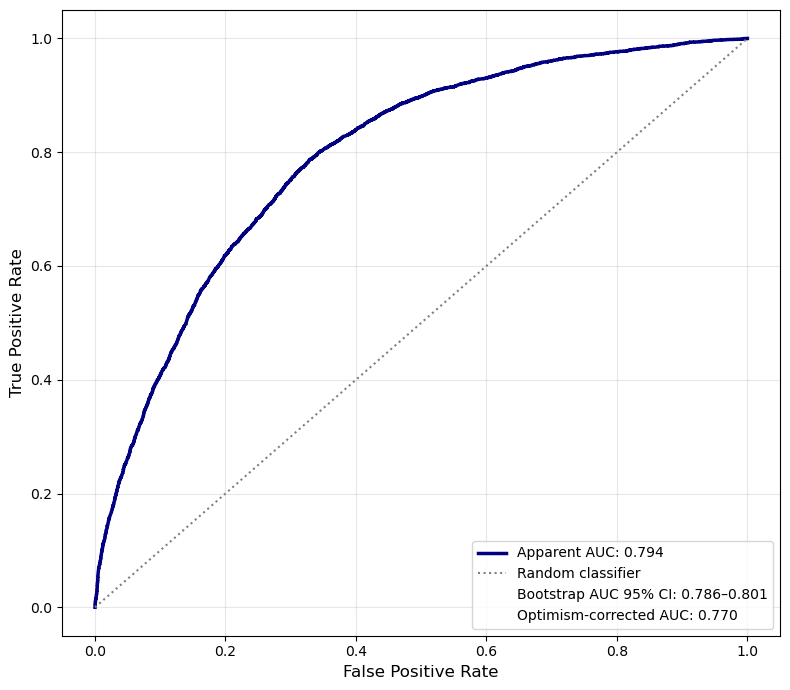

In [12]:
# PLot discrimination

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.base import clone

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# STEP 1: Apparent ROC
fpr_app, tpr_app, _ = roc_curve(y, y_proba)


# STEP 2: Plot
plt.figure(figsize=(8, 7))

# Apparent ROC curve
plt.plot(
    fpr_app,
    tpr_app,
    lw=2.5,
    color="navy",
    label=f"Apparent AUC: {apparent_auc:.3f}"
)

# Chance line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":",
    color="grey",
    lw=1.5,
    label="Random classifier"
)

# STEP 3: Add summary statistics to legend

plt.plot([], [], ' ',
         label=f"Bootstrap AUC 95% CI: {ci_lower:.3f}–{ci_upper:.3f}")

plt.plot([], [], ' ',
         label=f"Optimism-corrected AUC: {optimism_corrected_auc:.3f}")

# STEP 4: Formatting

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("", fontsize=14)

plt.legend(loc="lower right", frameon=True)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

FEATURE IMPORTANCE (EXTENDED MODEL)
Total features: 24

Top 10 Features:
--------------------------------------------------
 1. parity                         0.6677 (66.8%)
 2. mother_height                  0.0427 (4.3%)
 3. smoke_b20                      0.0376 (3.8%)
 4. gest_weeks                     0.0342 (3.4%)
 5. bmi                            0.0341 (3.4%)
 6. mother_age                     0.0295 (2.9%)
 7. mother_weight                  0.0227 (2.3%)
 8. cob_region                     0.0206 (2.1%)
 9. ascl_group_rec_Austro-Asiatic Languages 0.0190 (1.9%)
10. pre_diab                       0.0184 (1.8%)


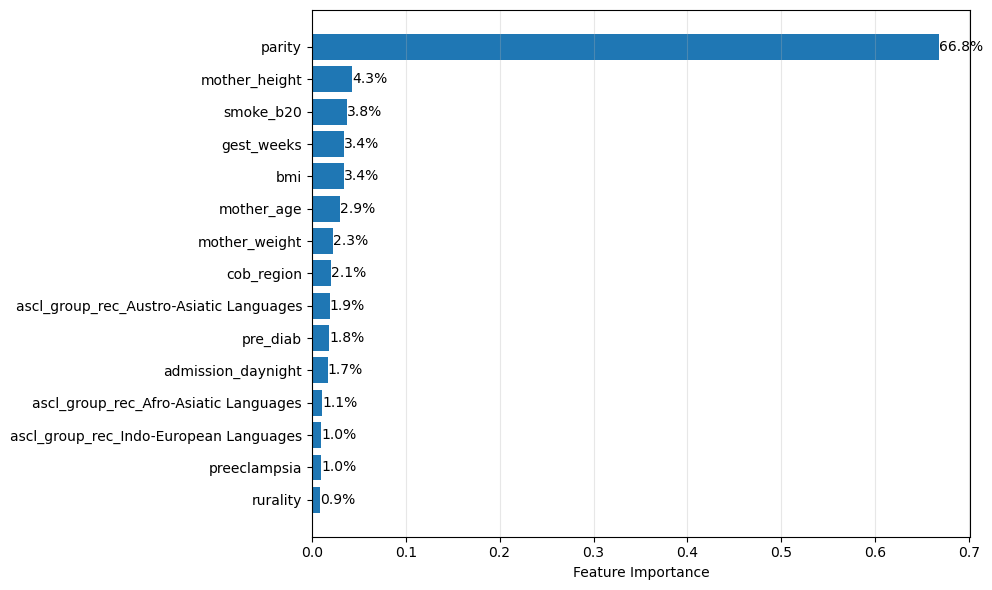


SUMMARY
Most important feature: parity (0.6677)
Top 3 features contribution: 74.8%


In [251]:
import numpy as np
import matplotlib.pyplot as plt

print("FEATURE IMPORTANCE (EXTENDED MODEL)")
print("="*50)

# STEP 1: Extract model (FIXED NAME)
xgb_model = new_pipeline.named_steps["classifier"]

# STEP 2: Feature names
feature_names = X_extended.columns
feature_importance = xgb_model.feature_importances_

# STEP 3: Pair and sort
feature_imp_pairs = list(zip(feature_names, feature_importance))
feature_imp_pairs.sort(key=lambda x: x[1], reverse=True)

# Create data for exporting to csv
feature_imp_pairs_extended = feature_imp_pairs.copy()

total_importance = np.sum(feature_importance)

print(f"Total features: {len(feature_names)}")

print("\nTop 10 Features:")
print("-" * 50)

for i, (feat, imp) in enumerate(feature_imp_pairs[:10], 1):
    print(f"{i:2d}. {feat:<30} {imp:.4f} ({imp/total_importance*100:.1f}%)")

pd.DataFrame(feature_imp_pairs_extended,
             columns=["Feature", "Importance"]).to_csv(
    "feature_importance_extended.csv", index=False)

# STEP 4: PLOT (TOP 15)
top_n = 15
top_features = feature_imp_pairs[:top_n]

features = [f[0] for f in top_features]
importances = [f[1] for f in top_features]

plt.figure(figsize=(10, 6))
y_pos = np.arange(len(features))

plt.barh(y_pos, importances)

plt.yticks(y_pos, features)
plt.xlabel("Feature Importance")
plt.title("")
plt.gca().invert_yaxis()

# percentage labels
for i, imp in enumerate(importances):
    plt.text(
        imp,
        i,
        f"{imp/total_importance*100:.1f}%",
        va="center"
    )

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# STEP 5: Summary
top3 = sum([imp for _, imp in feature_imp_pairs[:3]])
top1 = feature_imp_pairs[0]

print("\nSUMMARY")
print("="*50)
print(f"Most important feature: {top1[0]} ({top1[1]:.4f})")
print(f"Top 3 features contribution: {top3/total_importance*100:.1f}%")

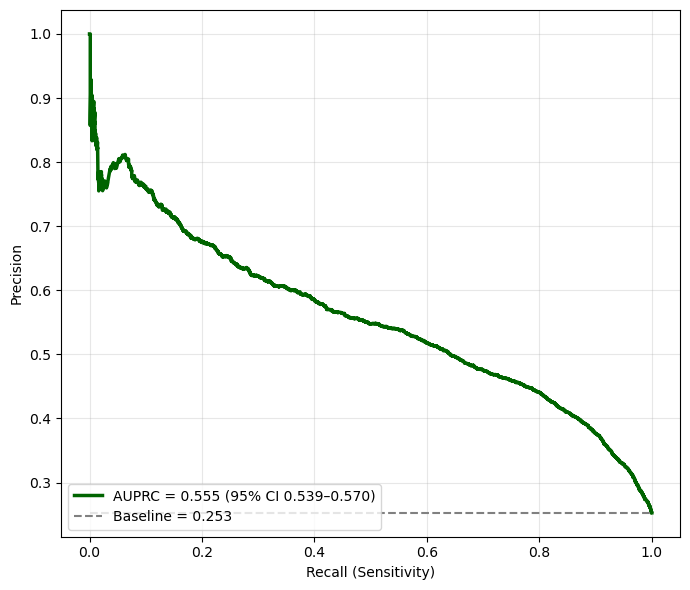

In [13]:
# Precision-Recall Curve #

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score


# STEP 1: Predictions
y_proba = new_pipeline.predict_proba(X_extended)[:, 1]
y = np.array(y)

auprc = average_precision_score(y, y_proba)

# STEP 2: Bootstrap CI

n_bootstraps = 1000
rng = np.random.RandomState(42)

boot_auprc = []

for i in range(n_bootstraps):
    idx = rng.randint(0, len(y), len(y))

    if len(np.unique(y[idx])) < 2:
        continue

    score = average_precision_score(y[idx], y_proba[idx])
    boot_auprc.append(score)

boot_auprc = np.array(boot_auprc)

ci_lower = np.percentile(boot_auprc, 2.5)
ci_upper = np.percentile(boot_auprc, 97.5)

# STEP 3: Precision–Recall curve

precision, recall, _ = precision_recall_curve(y, y_proba)

plt.figure(figsize=(7,6))

plt.plot(
    recall,
    precision,
    lw=2.5,
    color="darkgreen",
    label=f"AUPRC = {auprc:.3f} (95% CI {ci_lower:.3f}–{ci_upper:.3f})"
)

# baseline
baseline = np.mean(y)
plt.hlines(
    baseline, 0, 1,
    colors="gray",
    linestyles="--",
    label=f"Baseline = {baseline:.3f}"
)

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

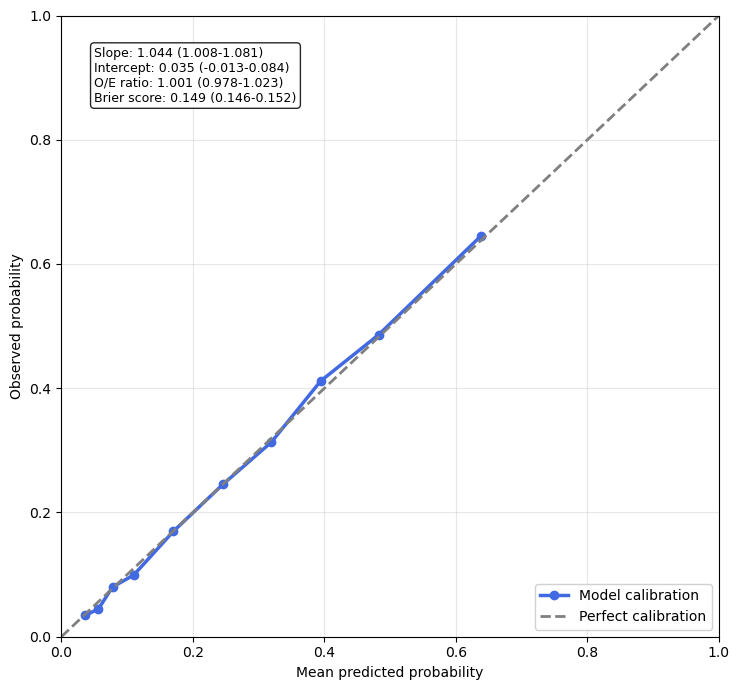

In [14]:
# Model calibration #

import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
from scipy.special import logit

# STEP 1: Predictions

y_proba = new_pipeline.predict_proba(X_extended)[:, 1]
y = np.array(y)

# clip probabilities for stability
p = np.clip(y_proba, 1e-6, 1 - 1e-6)

# STEP 2: Calibration slope + intercept (HARRELL METHOD)

lp = logit(p).reshape(-1, 1)

X = sm.add_constant(lp)

cal_model = sm.Logit(y, X).fit(disp=False)

cal_intercept = cal_model.params[0]
cal_slope = cal_model.params[1]

# STEP 3: Brier score + O/E ratio

brier = brier_score_loss(y, y_proba)
oe_ratio = np.sum(y_proba) / np.sum(y)

# STEP 4: Calibration curve

prob_true, prob_pred = calibration_curve(
    y, y_proba, n_bins=10, strategy="quantile"
)

# STEP 4.1: Bootstrap 95% CIs
np.random.seed(123)
B, n = 1000, len(y)
boot = []

for _ in range(B):
    i = np.random.choice(n, n, replace=True)
    yi, pi = y[i], y_proba[i]

    if len(np.unique(yi)) < 2:
        continue

    try:
        lp_b = logit(np.clip(pi, 1e-6, 1-1e-6)).reshape(-1, 1)
        m = sm.Logit(yi, sm.add_constant(lp_b)).fit(disp=False)
        boot.append([
            m.params[1], m.params[0],
            np.sum(pi) / np.sum(yi),
            brier_score_loss(yi, pi)
        ])
    except Exception:
        continue

boot = np.asarray(boot)
ci_low, ci_high = np.percentile(boot, [2.5, 97.5], axis=0)

# STEP 5: Plot

plt.figure(figsize=(7.5, 7))

# model calibration
plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2.5,
    color="royalblue",
    label="Model calibration"
)

# perfect calibration
plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    linewidth=2,
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed probability")
plt.title("")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)

# STEP 6: Metrics box with 95% CIs
metrics_text = (
    f"Slope: {cal_slope:.3f} ({ci_low[0]:.3f}-{ci_high[0]:.3f})\n"
    f"Intercept: {cal_intercept:.3f} ({ci_low[1]:.3f}-{ci_high[1]:.3f})\n"
    f"O/E ratio: {oe_ratio:.3f} ({ci_low[2]:.3f}-{ci_high[2]:.3f})\n"
    f"Brier score: {brier:.3f} ({ci_low[3]:.3f}-{ci_high[3]:.3f})"
)

plt.gca().text(
    0.05, 0.95,
    metrics_text,
    transform=plt.gca().transAxes,
    fontsize=9,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
)

# STEP 7: Legend 
plt.legend(
    loc="lower right",
    frameon=True,
    fancybox=True,
    framealpha=0.9
)

plt.tight_layout()
plt.show()

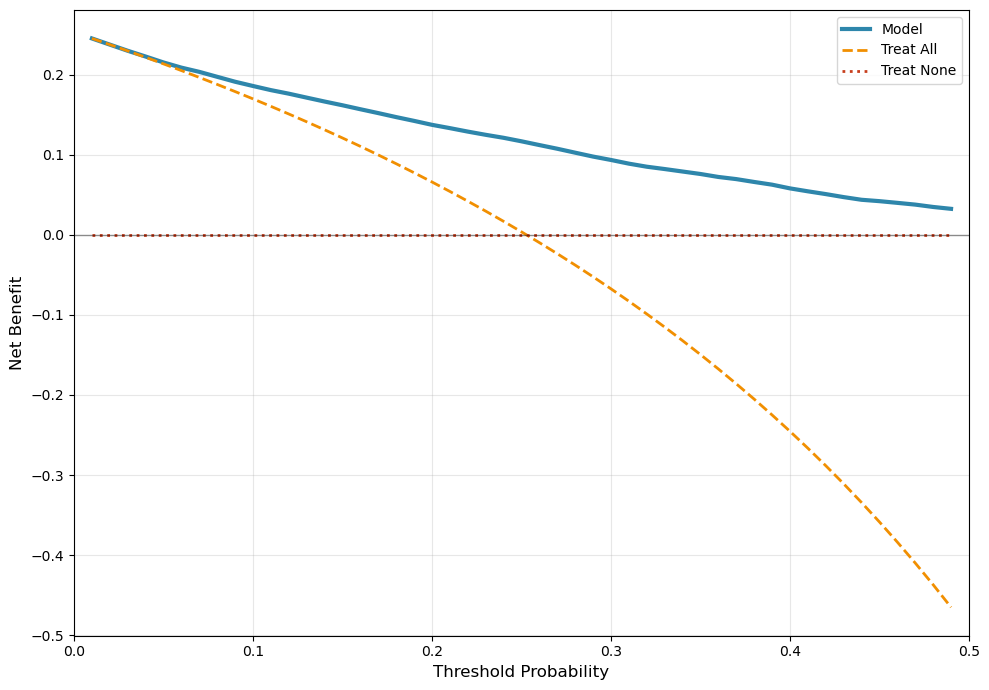


DCA SUMMARY
✓ Model outperforms Treat All: 0.03 – 0.49
✓ Best threshold: 0.01 (Net Benefit: 0.2452)
✓ Model outperforms Treat None: 0.01 – 0.49


In [15]:
# Decision Curve Analysis #

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# INPUTS

pred_prob = new_pipeline.predict_proba(X_extended)[:, 1]
y = y.values if hasattr(y, "values") else np.array(y)

# STEP 1: Net benefit function 
def net_benefit(y_true, y_prob, threshold):
    if threshold <= 0 or threshold >= 1:
        return np.nan

    y_pred = (y_prob >= threshold).astype(int)

    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    n = len(y_true)

    return (tp / n) - (fp / n) * (threshold / (1 - threshold))

# STEP 2: Threshold range 

thresholds = np.arange(0.01, 0.50, 0.01)

model_nb = []
treat_all_nb = []
treat_none_nb = np.zeros_like(thresholds)

event_rate = np.mean(y)

# STEP 3: Compute net benefit curves

for t in thresholds:

    # model
    model_nb.append(net_benefit(y, pred_prob, t))

    # treat-all (correct formula)
    nb_all = event_rate - (1 - event_rate) * (t / (1 - t))
    treat_all_nb.append(nb_all)

model_nb = np.array(model_nb)
treat_all_nb = np.array(treat_all_nb)

# STEP 4: Plot DCA
fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(thresholds, model_nb,
        label="Model",
        linewidth=3,
        color='#2E86AB')

ax.plot(thresholds, treat_all_nb,
        linestyle="--",
        label="Treat All",
        linewidth=2,
        color='#F18F01')

ax.plot(thresholds, treat_none_nb,
        linestyle=":",
        label="Treat None",
        linewidth=2,
        color='#C73E1D')

ax.axhline(0, color='black', linewidth=1, alpha=0.4)

ax.set_xlim(0, 0.50)



ax.set_xlabel("Threshold Probability", fontsize=12)
ax.set_ylabel("Net Benefit", fontsize=12)
ax.set_title("", fontsize=14)

ax.grid(alpha=0.3)
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

# STEP 5: Analysis table
net_benefit_df = pd.DataFrame({
    "threshold": thresholds,
    "model": model_nb,
    "treat_all": treat_all_nb,
    "treat_none": treat_none_nb
})

# model usefulness regions
better_than_all = net_benefit_df[net_benefit_df["model"] > net_benefit_df["treat_all"]]
better_than_none = net_benefit_df[net_benefit_df["model"] > 0]

# STEP 6: Interpretation

print("\nDCA SUMMARY")
print("=" * 50)

if len(better_than_all) > 0:
    print(f"✓ Model outperforms Treat All: "
          f"{better_than_all['threshold'].min():.2f} – "
          f"{better_than_all['threshold'].max():.2f}")

    best_idx = net_benefit_df["model"].idxmax()
    print(f"✓ Best threshold: {net_benefit_df.loc[best_idx, 'threshold']:.2f} "
          f"(Net Benefit: {net_benefit_df.loc[best_idx, 'model']:.4f})")
else:
    print("⚠ Model does NOT outperform Treat All strategy")

if len(better_than_none) > 0:
    print(f"✓ Model outperforms Treat None: "
          f"{better_than_none['threshold'].min():.2f} – "
          f"{better_than_none['threshold'].max():.2f}")

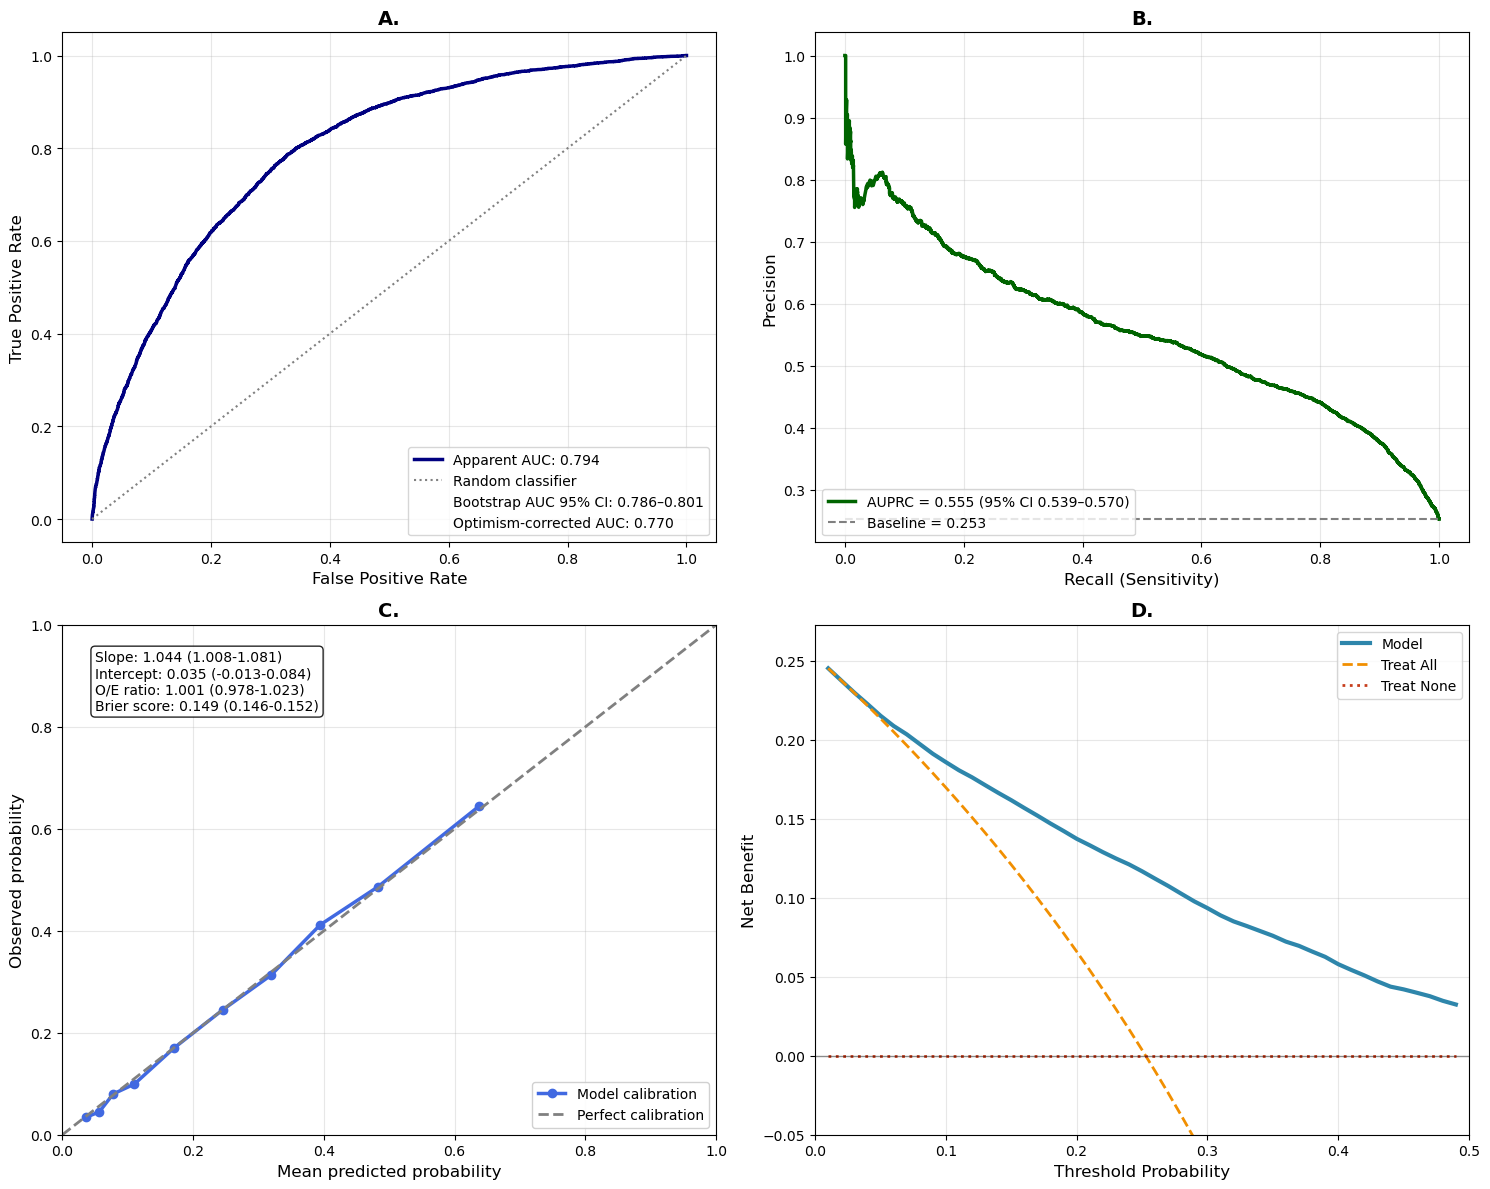

In [16]:
# Combine the 4 plots in a grid #

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve
import statsmodels.api as sm
from scipy.special import logit
import pandas as pd

# Create 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# PLOT A: ROC Curve (top-left) - CORRECTED
ax_a = axes[0, 0]
fpr_app, tpr_app, _ = roc_curve(y, y_proba)

# Define the correct CI values from your bootstrap analysis
apparent_auc = 0.794
ci_lower = 0.786  # Correct lower CI
ci_upper = 0.801  # Correct upper CI
optimism_corrected_auc = 0.770

ax_a.plot(fpr_app, tpr_app, lw=2.5, color="navy", 
          label=f"Apparent AUC: {apparent_auc:.3f}")
ax_a.plot([0, 1], [0, 1], linestyle=":", color="grey", lw=1.5, 
          label="Random classifier")
ax_a.plot([], [], ' ', label=f"Bootstrap AUC 95% CI: {ci_lower:.3f}–{ci_upper:.3f}")
ax_a.plot([], [], ' ', label=f"Optimism-corrected AUC: {optimism_corrected_auc:.3f}")

ax_a.set_xlabel("False Positive Rate", fontsize=12)
ax_a.set_ylabel("True Positive Rate", fontsize=12)
ax_a.set_title("A.", fontsize=14, fontweight='bold')
ax_a.legend(loc="lower right", frameon=True)
ax_a.grid(alpha=0.3)

# PLOT B: Precision-Recall Curve (top-right)
ax_b = axes[0, 1]
y_proba = new_pipeline.predict_proba(X_extended)[:, 1]
y = np.array(y)
auprc = average_precision_score(y, y_proba)

# Bootstrap CI for AUPRC
n_bootstraps = 1000
rng = np.random.RandomState(42)
boot_auprc = []
for i in range(n_bootstraps):
    idx = rng.randint(0, len(y), len(y))
    if len(np.unique(y[idx])) < 2:
        continue
    score = average_precision_score(y[idx], y_proba[idx])
    boot_auprc.append(score)

boot_auprc = np.array(boot_auprc)
ci_lower_pr = np.percentile(boot_auprc, 2.5)
ci_upper_pr = np.percentile(boot_auprc, 97.5)

precision, recall, _ = precision_recall_curve(y, y_proba)
baseline = np.mean(y)

ax_b.plot(recall, precision, lw=2.5, color="darkgreen",
          label=f"AUPRC = {auprc:.3f} (95% CI {ci_lower_pr:.3f}–{ci_upper_pr:.3f})")
ax_b.hlines(baseline, 0, 1, colors="gray", linestyles="--", 
            label=f"Baseline = {baseline:.3f}")

ax_b.set_xlabel("Recall (Sensitivity)", fontsize=12)
ax_b.set_ylabel("Precision", fontsize=12)
ax_b.set_title("B.", fontsize=14, fontweight='bold')
ax_b.legend(loc="lower left")
ax_b.grid(alpha=0.3)

# PLOT C: Calibration Plot (bottom-left)
ax_c = axes[1, 0]
# Clip probabilities for stability
p = np.clip(y_proba, 1e-6, 1 - 1e-6)

# Calibration slope + intercept
lp = logit(p).reshape(-1, 1)
X = sm.add_constant(lp)
cal_model = sm.Logit(y, X).fit(disp=False)
cal_intercept = cal_model.params[0]
cal_slope = cal_model.params[1]

# Brier score + O/E ratio
brier = brier_score_loss(y, y_proba)
oe_ratio = np.sum(y_proba) / np.sum(y)

# Calibration curve
prob_true, prob_pred = calibration_curve(y, y_proba, n_bins=10, strategy="quantile")

# Bootstrap 95% CIs for calibration metrics
np.random.seed(123)
n, B = len(y), 1000
boot = []

for _ in range(B):
    i = np.random.choice(n, n, replace=True)
    yi, pi = y[i], y_proba[i]

    if len(np.unique(yi)) < 2:
        continue

    try:
        lp_b = logit(np.clip(pi, 1e-6, 1-1e-6)).reshape(-1, 1)
        m = sm.Logit(yi, sm.add_constant(lp_b)).fit(disp=False)
        boot.append([
            m.params[1], m.params[0],
            np.sum(pi) / np.sum(yi),
            brier_score_loss(yi, pi)
        ])
    except Exception:
        continue

boot = np.asarray(boot)
ci_low, ci_high = np.percentile(boot, [2.5, 97.5], axis=0)

ax_c.plot(prob_pred, prob_true, marker="o", linewidth=2.5, color="royalblue",
          label="Model calibration")
ax_c.plot([0, 1], [0, 1], "--", color="gray", linewidth=2, 
          label="Perfect calibration")

ax_c.set_xlabel("Mean predicted probability", fontsize=12)
ax_c.set_ylabel("Observed probability", fontsize=12)
ax_c.set_title("C.", fontsize=14, fontweight='bold')
ax_c.set_xlim(0, 1)
ax_c.set_ylim(0, 1)
ax_c.grid(alpha=0.3)

# Add metrics box with 95% CIs
metrics_text = (
    f"Slope: {cal_slope:.3f} ({ci_low[0]:.3f}-{ci_high[0]:.3f})\n"
    f"Intercept: {cal_intercept:.3f} ({ci_low[1]:.3f}-{ci_high[1]:.3f})\n"
    f"O/E ratio: {oe_ratio:.3f} ({ci_low[2]:.3f}-{ci_high[2]:.3f})\n"
    f"Brier score: {brier:.3f} ({ci_low[3]:.3f}-{ci_high[3]:.3f})"
)

ax_c.text(0.05, 0.95, metrics_text, transform=ax_c.transAxes, fontsize=10,
          verticalalignment="top", 
          bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
ax_c.legend(loc="lower right", frameon=True, fancybox=True, framealpha=0.9)

# PLOT D: Decision Curve Analysis (bottom-right)
ax_d = axes[1, 1]

# Net benefit function
def net_benefit(y_true, y_prob, threshold):
    if threshold <= 0 or threshold >= 1:
        return np.nan
    y_pred = (y_prob >= threshold).astype(int)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    n = len(y_true)
    return (tp / n) - (fp / n) * (threshold / (1 - threshold))

# Threshold range and calculations
thresholds = np.arange(0.01, 0.50, 0.01)
model_nb = []
treat_all_nb = []
treat_none_nb = np.zeros_like(thresholds)
event_rate = np.mean(y)

for t in thresholds:
    model_nb.append(net_benefit(y, y_proba, t))
    nb_all = event_rate - (1 - event_rate) * (t / (1 - t))
    treat_all_nb.append(nb_all)

model_nb = np.array(model_nb)
treat_all_nb = np.array(treat_all_nb)

ax_d.plot(thresholds, model_nb, label="Model", linewidth=3, color='#2E86AB')
ax_d.plot(thresholds, treat_all_nb, linestyle="--", label="Treat All", 
          linewidth=2, color='#F18F01')
ax_d.plot(thresholds, treat_none_nb, linestyle=":", label="Treat None", 
          linewidth=2, color='#C73E1D')
ax_d.axhline(0, color='black', linewidth=1, alpha=0.4)

# Set axis limits
max_nb = max(np.max(model_nb), event_rate)
ax_d.set_ylim(-0.05, max_nb + 0.02)
ax_d.set_xlim(0, 0.50)

ax_d.set_xlabel("Threshold Probability", fontsize=12)
ax_d.set_ylabel("Net Benefit", fontsize=12)
ax_d.set_title("D.", fontsize=14, fontweight='bold')
ax_d.grid(alpha=0.3)
ax_d.legend(loc='upper right', frameon=True)

# Save as high-resolution TIFF
plt.savefig('Extended_model_performance_plots.tiff', 
            dpi=300,          
            format='tiff',     
            bbox_inches='tight', 
            facecolor='white',   
            edgecolor='none')

# Adjust layout and show
plt.tight_layout()
plt.show()